# Expected Goals (xG) from scratch

A single, reproducible notebook that builds an Expected Goals model the way
David Sumpter teaches it in *Soccermatics* / *Friends of Tracking*: start from
the **simplest interpretable model** — a logistic regression on shot **distance**
and **angle** — interpret it fully, and only then reach for gradient boosting.

Interpretability and **calibration** are treated as first-class results. A model
whose predicted xG does not match observed conversion rates is not useful, no
matter how high its AUC.

**Pipeline**
0. Overview, data credit, library versions
1. Data procurement (StatsBomb open data via `mplsoccer.Sbopen`)
2. Cleaning and shot filtering
3. Feature engineering *with validation*
4. Baseline logistic model (distance + angle) + interpretation
5. Extended logistic model
6. Gradient boosting model
7. Evaluation, calibration, and StatsBomb-xG benchmark
8. Visualisations (`mplsoccer`)
9. Written conclusions

The notebook runs top-to-bottom on a fresh kernel with no manual intervention.
Downloaded shots are cached to a local parquet file so re-runs are fast; the
first run pulls everything from the StatsBomb open-data repo.

## Data credit

All data used here is **StatsBomb free open data**
(<https://github.com/statsbomb/open-data>), accessed through the `mplsoccer`
`Sbopen` parser. No paid API and no login are used.

> **Data provided by StatsBomb.** This project uses StatsBomb's free open data,
> which StatsBomb requires be attributed. See their
> [open-data repository](https://github.com/statsbomb/open-data) and user
> agreement.

The StatsBomb **Open Data Specification** (in that repo, under `doc/`) is the
reference used below for pitch dimensions and goalpost coordinates.

In [1]:
# --- Reproducibility: seeds + pinned library versions -----------------------
import sys, platform, random
import numpy as np

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

import pandas as pd
import scipy, sklearn, matplotlib, mplsoccer, xgboost, joblib, pyarrow
try:
    import statsbombpy
    sbpy_ver = getattr(statsbombpy, "__version__", "1.19.x (no __version__ attr)")
except Exception:
    sbpy_ver = "not imported"

print("Python        :", sys.version.split()[0], "|", platform.platform())
print("numpy         :", np.__version__)
print("pandas        :", pd.__version__)
print("scipy         :", scipy.__version__)
print("scikit-learn  :", sklearn.__version__)
print("matplotlib    :", matplotlib.__version__)
print("mplsoccer     :", mplsoccer.__version__)
print("xgboost       :", xgboost.__version__)
print("pyarrow       :", pyarrow.__version__)
print("joblib        :", joblib.__version__)
print("statsbombpy   :", sbpy_ver)
print("random seed   :", RANDOM_SEED)

Python        : 3.12.2 | macOS-26.5.1-arm64-arm-64bit
numpy         : 2.4.6
pandas        : 3.0.3
scipy         : 1.17.1
scikit-learn  : 1.9.0
matplotlib    : 3.10.9
mplsoccer     : 1.6.1
xgboost       : 3.3.0
pyarrow       : 24.0.0
joblib        : 1.5.3
statsbombpy   : 1.19.x (no __version__ attr)
random seed   : 42


### Pinned versions used to author this notebook

Exact versions this notebook was written and executed against. Different versions
should give materially the same results, with small numeric differences possible.

| Library | Version |
|---|---|
| Python | 3.12.2 |
| numpy | 2.4.6 |
| pandas | 3.0.3 |
| scipy | 1.17.1 |
| scikit-learn | 1.9.0 |
| matplotlib | 3.10.9 |
| mplsoccer | 1.6.1 |
| xgboost | 3.3.0 |
| pyarrow | 24.0.0 |
| joblib | 1.5.3 |
| statsbombpy | 1.19.0 |

**Competitions/seasons pulled** (live list + counts printed in Section 1):
FIFA World Cup 2018, FIFA World Cup 2022, UEFA Euro 2020, UEFA Euro 2024.

## 1. Data procurement

We load `competitions.json` first, print every available `competition_id` /
`season_id` combination, then **choose** a set that yields several thousand shots.

**Choice and why.** Four recent men's international tournaments —
**FIFA World Cup 2018 & 2022**, **UEFA Euro 2020 & 2024**. Reasons:

* full-tournament coverage (every match), so no team-selection bias like the
  partial club-season datasets in the open data;
* modern laws / playing style (all post-2018), avoiding era effects from mixing
  very different decades;
* every match ships **shot freeze-frames**, enabling optional defender /
  goalkeeper features later.

Together ~6,000 shots — comfortably above the "few thousand" target.

In [2]:
from mplsoccer import Sbopen

parser = Sbopen()  # reads StatsBomb open data straight from the public GitHub repo

comp = parser.competition()
print("competitions.json ->", comp.shape[0], "competition-season rows")
print("columns:", list(comp.columns))

menu = (comp[["competition_id", "competition_name",
              "season_id", "season_name", "competition_gender"]]
        .sort_values(["competition_name", "season_name"])
        .reset_index(drop=True))
with pd.option_context("display.max_rows", None):
    print(menu.to_string())

competitions.json -> 80 competition-season rows
columns: ['competition_id', 'season_id', 'country_name', 'competition_name', 'competition_gender', 'competition_youth', 'competition_international', 'season_name', 'match_updated', 'match_updated_360', 'match_available_360', 'match_available']
    competition_id         competition_name  season_id season_name competition_gender
0                9            1. Bundesliga         27   2015/2016               male
1                9            1. Bundesliga        281   2023/2024               male
2             1267   African Cup of Nations        107        2023               male
3               16         Champions League        276   1970/1971               male
4               16         Champions League         71   1971/1972               male
5               16         Champions League        277   1972/1973               male
6               16         Champions League         76   1999/2000               male
7               16  

In [3]:
# --- The set we CHOOSE to pull ---------------------------------------------
CHOSEN = {
    (43, 3):   "FIFA World Cup 2018",
    (43, 106): "FIFA World Cup 2022",
    (55, 43):  "UEFA Euro 2020",
    (55, 282): "UEFA Euro 2024",
}

# Fail loudly if a chosen combo is not actually in the open data.
avail = set(zip(comp["competition_id"], comp["season_id"]))
missing = [k for k in CHOSEN if k not in avail]
assert not missing, f"Chosen combos not in open data: {missing}"
print("All chosen competition/season combos are available:")
for (c, s), label in CHOSEN.items():
    print(f"  competition_id={c:>3}  season_id={s:>3}  ->  {label}")

All chosen competition/season combos are available:
  competition_id= 43  season_id=  3  ->  FIFA World Cup 2018
  competition_id= 43  season_id=106  ->  FIFA World Cup 2022
  competition_id= 55  season_id= 43  ->  UEFA Euro 2020
  competition_id= 55  season_id=282  ->  UEFA Euro 2024


In [4]:
# --- Match list for every chosen tournament ---------------------------------
match_frames = []
for (c, s), label in CHOSEN.items():
    mm = parser.match(c, s).assign(competition_id=c, season_id=s, tournament=label)
    match_frames.append(mm)
    print(f"{label:<22}: {len(mm):>3} matches")

matches = pd.concat(match_frames, ignore_index=True)
print("-" * 40)
print(f"TOTAL MATCHES: {len(matches)}")

FIFA World Cup 2018   :  64 matches


FIFA World Cup 2022   :  64 matches


UEFA Euro 2020        :  51 matches


UEFA Euro 2024        :  51 matches
----------------------------------------
TOTAL MATCHES: 230


In [5]:
# --- Pull shot events for every match --------------------------------------
# Sbopen.event() -> (events, related, freeze_frames, tactics). Fetching is
# HTTP-bound, so a small thread pool speeds it up. Cache to parquet for fast
# re-runs on a fresh kernel.
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

CACHE_DIR = Path("data_cache"); CACHE_DIR.mkdir(exist_ok=True)
SHOTS_CACHE = CACHE_DIR / "shots_raw.parquet"
FREEZE_CACHE = CACHE_DIR / "freeze_raw.parquet"

def _fetch_shots(match_id: int):
    """Return (shots_df, freeze_df) for one match."""
    events, _rel, freeze, _tac = parser.event(int(match_id))
    shots = events[events["type_name"] == "Shot"].copy()
    freeze = freeze[freeze["id"].isin(set(shots["id"]))].copy()
    return shots, freeze

if SHOTS_CACHE.exists() and FREEZE_CACHE.exists():
    shots_raw = pd.read_parquet(SHOTS_CACHE)
    freeze_raw = pd.read_parquet(FREEZE_CACHE)
    print(f"Loaded cached shots: {len(shots_raw)} rows from {SHOTS_CACHE}")
else:
    match_ids = matches["match_id"].tolist()
    with ThreadPoolExecutor(max_workers=8) as ex:
        results = list(ex.map(_fetch_shots, match_ids))
    shots_raw = pd.concat([r[0] for r in results], ignore_index=True)
    freeze_raw = pd.concat([r[1] for r in results], ignore_index=True)
    label_map = matches.set_index("match_id")["tournament"].to_dict()
    shots_raw["tournament"] = shots_raw["match_id"].map(label_map)
    shots_raw.to_parquet(SHOTS_CACHE)
    freeze_raw.to_parquet(FREEZE_CACHE)
    print(f"Pulled and cached {len(shots_raw)} shots from {len(match_ids)} matches")

print("\nShots per tournament:")
print(shots_raw["tournament"].value_counts())
print("\nTOTAL SHOTS PULLED:", len(shots_raw))

Loaded cached shots: 5829 rows from data_cache/shots_raw.parquet

Shots per tournament:
tournament
FIFA World Cup 2018    1706
FIFA World Cup 2022    1494
UEFA Euro 2024         1340
UEFA Euro 2020         1289
Name: count, dtype: int64

TOTAL SHOTS PULLED: 5829


## 2. Cleaning and shot filtering

We already filtered to `type_name == "Shot"`. Now we:

1. **Confirm the target label.** We inspect `outcome_name` and use the exact
   string that denotes a goal — we do not assume it.
2. **Penalties** — dropped. A penalty is a fixed-geometry shot (12 yards, empty
   run-up) whose scoring rate is essentially constant (~0.75). Including them
   would distort the distance/angle relationship for open-play shots. Modelling
   them separately adds little, so we remove them and say so here.
3. **Own goals** — not present. In StatsBomb, own goals are separate event types
   (`Own Goal For` / `Own Goal Against`), **not** `Shot` events, so filtering to
   shots already excludes them. We verify no own-goal outcome leaks in.
4. **Set-piece shots** (direct free kicks, and shots originating from corners /
   free kicks in open play) — **kept**, and flagged via `sub_type_name` and
   `play_pattern_name` so the models can use that context. Direct free kicks have
   unusual geometry; keeping them but flagging is a deliberate choice.

In [6]:
# --- Confirm the exact goal label ------------------------------------------
print("Shot outcome_name value counts:")
print(shots_raw["outcome_name"].value_counts(dropna=False))

GOAL_LABEL = "Goal"
assert GOAL_LABEL in set(shots_raw["outcome_name"].dropna()), "No 'Goal' outcome found!"
print(f"\nUsing outcome_name == '{GOAL_LABEL}' as the positive (goal) class.")

# Sanity: no own-goal outcome strings present among shots.
og = shots_raw["outcome_name"].astype("string").str.contains("Own", case=False, na=False)
print("Rows with an 'Own'-goal outcome among shots:", int(og.sum()), "(expected 0)")

Shot outcome_name value counts:
outcome_name
Off T               1833
Blocked             1559
Saved               1286
Goal                 659
Wayward              351
Post                 116
Saved to Post         13
Saved Off Target      12
Name: count, dtype: int64

Using outcome_name == 'Goal' as the positive (goal) class.
Rows with an 'Own'-goal outcome among shots: 0 (expected 0)


In [7]:
# --- Shot sub-types present (how penalties/free kicks are labelled) ---------
print("sub_type_name counts:\n", shots_raw["sub_type_name"].value_counts(dropna=False))

n_before = len(shots_raw)
shots = shots_raw[shots_raw["sub_type_name"] != "Penalty"].copy()
print(f"\nDropped {n_before - len(shots)} penalties. Remaining shots: {len(shots)}")

# --- Build the binary target ------------------------------------------------
shots["goal"] = (shots["outcome_name"] == GOAL_LABEL).astype(int)
overall_rate = shots["goal"].mean()
print(f"Overall conversion rate (goals / shots): {overall_rate:.3f} "
      f"({shots['goal'].sum()} goals / {len(shots)} shots)")

sub_type_name counts:
 sub_type_name
Open Play    5388
Penalty       223
Free Kick     212
Corner          6
Name: count, dtype: int64

Dropped 223 penalties. Remaining shots: 5606
Overall conversion rate (goals / shots): 0.090 (507 goals / 5606 shots)


In [8]:
# --- Coordinate sanity check (are all shots in the attacking half?) ---------
# StatsBomb events are always oriented so the attacking team shoots toward x=120
# on a 120 x 80 pitch. Verify before trusting the geometry.
print("x range: %.1f .. %.1f" % (shots["x"].min(), shots["x"].max()))
print("y range: %.1f .. %.1f" % (shots["y"].min(), shots["y"].max()))

# Coordinates must be valid pitch positions (0..120 x 0..80, small rounding ok).
assert shots["x"].between(0, 121).all() and shots["y"].between(0, 81).all(), \
    "Shot coordinates outside the pitch!"
# Orientation check: StatsBomb normalises every shot to attack toward x=120, so
# the overwhelming majority sit deep in the attacking half. A median well above
# 100 confirms the data is oriented as expected (not mirrored).
assert shots["x"].median() > 100, "Shots do not appear oriented toward x=120!"
n_longrange = int((shots["x"] < 60).sum())
print(f"All shots oriented toward x=120 (median x = {shots['x'].median():.1f}).")
print(f"Long-range shots from own half (x < 60): {n_longrange} "
      f"({n_longrange/len(shots):.1%}) — kept; they simply get very low xG.")

# Drop the very few rows with missing location, if any (needed for geometry).
missing_loc = shots[["x", "y"]].isna().any(axis=1).sum()
print("Shots with missing x/y:", int(missing_loc))
shots = shots.dropna(subset=["x", "y"]).reset_index(drop=True)
print("Final clean shot count:", len(shots))

x range: 48.1 .. 120.1
y range: 0.7 .. 79.3
All shots oriented toward x=120 (median x = 105.1).
Long-range shots from own half (x < 60): 9 (0.2%) — kept; they simply get very low xG.
Shots with missing x/y: 0
Final clean shot count: 5606


## 3. Feature engineering (the heart of the project)

Every feature is derived from raw shot location and shot metadata — computed here,
not taken pre-baked. For each engineered feature we show a quick validation:
a distribution plot and the **conversion rate by binned value**, so it is clear
the feature behaves sensibly (closer + wider angle ⇒ higher scoring rate).

### 3.1 Pitch geometry and goalpost coordinates (verified)

From the StatsBomb Open Data Specification, the pitch is **120 × 80** (units are
"StatsBomb yards"). The goal is **8 units wide**, centred on the touchline at
`y = 40`. Therefore:

* right goalpost: **(120, 36)**
* left goalpost: **(120, 44)**
* goal centre: **(120, 40)**

We do not take this on faith — we verify it against the data: every *goal* must
cross the line at `x = 120` with `y` inside `[36, 44]`.

In [9]:
# --- Goalpost constants, then VERIFY against actual goals -------------------
GOAL_X = 120.0
GOAL_CENTER_Y = 40.0
POST_A_Y = 36.0   # one post
POST_B_Y = 44.0   # other post
GOAL_WIDTH = POST_B_Y - POST_A_Y  # = 8 StatsBomb yards

goals = shots[shots["goal"] == 1]
print("End-location of goals (where the ball crossed the line):")
print("  end_x : %.2f .. %.2f  (expect all = 120)" % (goals["end_x"].min(), goals["end_x"].max()))
print("  end_y : %.2f .. %.2f  (expect within [36, 44])" % (goals["end_y"].min(), goals["end_y"].max()))
print("  end_z : %.2f .. %.2f  (expect <= ~2.67, the crossbar height)" %
      (goals["end_z"].min(), goals["end_z"].max()))

# Allow small floating tolerance: the ball has width and StatsBomb records where
# it crossed the line, so values can sit a touch outside the exact post lines.
assert goals["end_x"].between(119.0, 121.0).all(), "Some goals did not cross near x=120?!"
frac_in_posts = goals["end_y"].between(POST_A_Y - 1.0, POST_B_Y + 1.0).mean()
print("\nFraction of goals crossing within [35, 45] in y: %.3f" % frac_in_posts)
assert frac_in_posts > 0.98, "Goals not clustered between the posts as expected?!"
print("Verified: goalposts at (120, 36) and (120, 44); centre (120, 40); width 8.")

End-location of goals (where the ball crossed the line):
  end_x : 119.00 .. 120.00  (expect all = 120)
  end_y : 35.80 .. 44.00  (expect within [36, 44])
  end_z : 0.00 .. 2.50  (expect <= ~2.67, the crossbar height)

Fraction of goals crossing within [35, 45] in y: 1.000
Verified: goalposts at (120, 36) and (120, 44); centre (120, 40); width 8.


### 3.2 Distance and angle — from first principles

**Distance** is the Euclidean distance from the shot to the centre of the goal:

$$ \text{distance} = \sqrt{(120 - x)^2 + (40 - y)^2} $$

**Angle** is the angle *subtended at the shot location by the two goalposts* — how
much of the goal mouth the shooter can "see". Let the two posts be
$P_A = (120, 36)$ and $P_B = (120, 44)$, and the shot be at $S = (x, y)$. Form
the vectors from the shot to each post:

$$ \vec{a} = P_A - S, \qquad \vec{b} = P_B - S. $$

The angle between them follows from the dot and cross products (the numerically
stable `atan2` form, equivalent to the law of cosines):

$$ \theta = \operatorname{atan2}\big(\,|\vec{a} \times \vec{b}|,\; \vec{a}\cdot\vec{b}\,\big). $$

This is well defined everywhere and always returns a value in $[0, \pi]$. A shot
on the goal line between the posts subtends a large angle (up to $\pi$); a shot
from a tight angle out wide subtends a small one. We store the angle in **radians**
for the model and also keep **degrees** for readable plots.

```
        P_A (120,36) ●───────● P_B (120,44)      goal mouth (width 8)
                       \     /
                        \ θ /   θ = angle subtended at the shot
                         \ /
                          ●  S = (x, y)  shot location
```

In [10]:
# --- Geometry functions (vectorised, documented) ---------------------------
def shot_distance(x, y, goal_x: float = GOAL_X, goal_y: float = GOAL_CENTER_Y):
    """Euclidean distance (StatsBomb yards) from shot (x, y) to the goal centre."""
    return np.sqrt((goal_x - x) ** 2 + (goal_y - y) ** 2)

def shot_angle(x, y, goal_x: float = GOAL_X,
               post_a_y: float = POST_A_Y, post_b_y: float = POST_B_Y):
    """Angle (radians, in [0, pi]) subtended at the shot by the two goalposts.

    Uses the atan2(|cross|, dot) form on the vectors from the shot to each post,
    which is numerically stable for all shot positions.
    """
    ax, ay = goal_x - x, post_a_y - y          # vector to post A
    bx, by = goal_x - x, post_b_y - y          # vector to post B
    dot = ax * bx + ay * by
    cross = ax * by - ay * bx
    return np.arctan2(np.abs(cross), dot)

# Quick self-checks on the angle function -----------------------------------
# 1) Standing on the goal line at the centre => should see nearly the whole goal
#    (angle approaches pi as we approach the line).
a_on_line = shot_angle(119.99, 40.0)
# 2) A penalty spot shot (12 yards out, central) angle:
a_pen = np.degrees(shot_angle(108.0, 40.0))
# 3) Acute angle from the byline near the post:
a_tight = np.degrees(shot_angle(119.0, 5.0))
print(f"angle just in front of centre goal (rad, ->pi): {a_on_line:.3f}")
print(f"angle at penalty spot (108,40):  {a_pen:5.1f} deg")
print(f"angle from wide byline (119,5):  {a_tight:5.1f} deg")

shots["distance"] = shot_distance(shots["x"].to_numpy(), shots["y"].to_numpy())
shots["angle"] = shot_angle(shots["x"].to_numpy(), shots["y"].to_numpy())
shots["angle_deg"] = np.degrees(shots["angle"])
print(shots[["x", "y", "distance", "angle", "angle_deg"]].describe().round(2))

angle just in front of centre goal (rad, ->pi): 3.137
angle at penalty spot (108,40):   36.9 deg
angle from wide byline (119,5):    0.4 deg
             x        y  distance    angle  angle_deg
count  5606.00  5606.00   5606.00  5606.00    5606.00
mean    104.07    39.81     18.82     0.45      25.70
std       8.58     9.94      8.51     0.29      16.35
min      48.10     0.70      0.76     0.00       0.00
25%      97.90    32.30     11.96     0.27      15.20
50%     105.10    40.00     18.27     0.35      19.83
75%     111.00    47.20     25.00     0.55      31.59
max     120.10    79.30     72.33     2.79     160.04


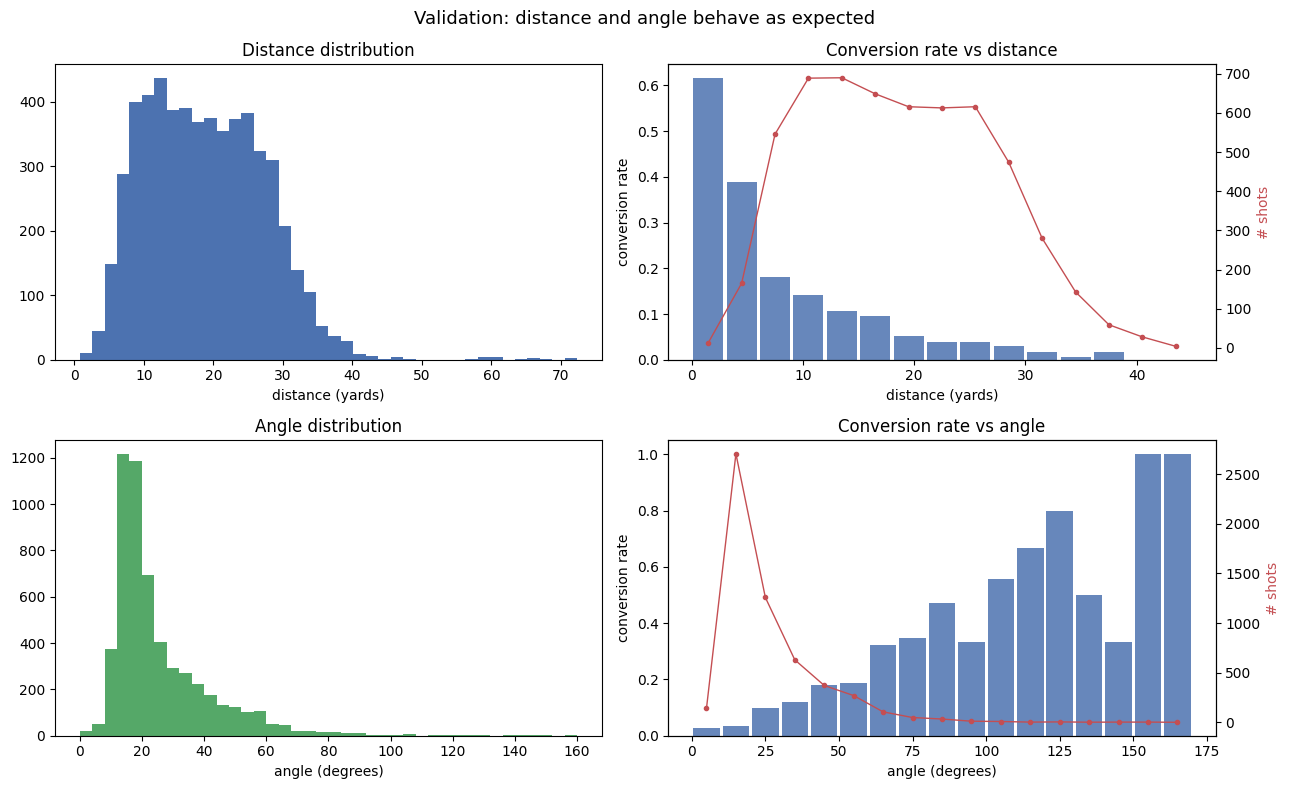

In [11]:
# --- Validation helper: conversion rate by binned feature ------------------
import matplotlib.pyplot as plt

def conversion_by_bin(df, col, bins, ax, xlabel):
    """Bar of conversion rate per bin + line for shot count; validates a feature."""
    cats = pd.cut(df[col], bins=bins)
    grp = df.groupby(cats, observed=True)["goal"].agg(["mean", "count"])
    centers = [iv.mid for iv in grp.index]
    ax.bar(centers, grp["mean"], width=(bins[1]-bins[0])*0.9,
           color="#4C72B0", alpha=0.85, label="conversion rate")
    ax.set_xlabel(xlabel); ax.set_ylabel("conversion rate")
    ax2 = ax.twinx()
    ax2.plot(centers, grp["count"], color="#C44E52", marker="o", ms=3, lw=1, label="# shots")
    ax2.set_ylabel("# shots", color="#C44E52")
    return grp

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
# Distance
axes[0,0].hist(shots["distance"], bins=40, color="#4C72B0"); axes[0,0].set_title("Distance distribution"); axes[0,0].set_xlabel("distance (yards)")
conversion_by_bin(shots, "distance", np.arange(0, 46, 3), axes[0,1], "distance (yards)")
axes[0,1].set_title("Conversion rate vs distance")
# Angle
axes[1,0].hist(shots["angle_deg"], bins=40, color="#55A868"); axes[1,0].set_title("Angle distribution"); axes[1,0].set_xlabel("angle (degrees)")
conversion_by_bin(shots, "angle_deg", np.arange(0, 185, 10), axes[1,1], "angle (degrees)")
axes[1,1].set_title("Conversion rate vs angle")
fig.suptitle("Validation: distance and angle behave as expected", fontsize=13)
fig.tight_layout(); plt.show()

**Reading the validation plots.** Conversion rate falls steeply with distance
(from ~35–40% inside a few yards to near zero beyond 30) and rises with the
subtended angle (wider view of the goal ⇒ more goals). Both are exactly the
monotonic relationships an xG model should capture, and they confirm the geometry
functions are correct. Note the two are correlated (close shots also tend to be
wide-angle), which we keep in mind when reading coefficients.

In [12]:
# --- Categorical / binary shot-context features ----------------------------
# Body part grouped to Foot / Head / Other.
def body_part_group(name: str) -> str:
    if name in ("Right Foot", "Left Foot"):
        return "Foot"
    if name == "Head":
        return "Head"
    return "Other"

shots["body_part"] = shots["body_part_name"].map(body_part_group)

# Shot situation: sub_type_name is Open Play / Free Kick (penalties already gone).
shots["shot_type"] = shots["sub_type_name"].fillna("Open Play")

# Play pattern (how the possession began): keep StatsBomb's label directly.
shots["play_pattern"] = shots["play_pattern_name"].fillna("Other")

# Binary context flags. In StatsBomb these are True or missing (missing = False).
for flag_src, flag_dst in [("under_pressure", "under_pressure"),
                           ("shot_first_time", "first_time"),
                           ("shot_one_on_one", "one_on_one"),
                           ("shot_open_goal", "open_goal")]:
    if flag_src in shots.columns:
        shots[flag_dst] = shots[flag_src].fillna(False).astype(bool).astype(int)
    else:
        shots[flag_dst] = 0
        print(f"NOTE: column '{flag_src}' absent; '{flag_dst}' set to 0.")

print(shots[["body_part", "shot_type", "play_pattern",
             "under_pressure", "first_time", "one_on_one", "open_goal"]].describe(include="all").T)

                 count unique           top  freq      mean       std  min  \
body_part         5606      3          Foot  4557       NaN       NaN  NaN   
shot_type         5606      3     Open Play  5388       NaN       NaN  NaN   
play_pattern      5606      9  Regular Play  1941       NaN       NaN  NaN   
under_pressure  5606.0    NaN           NaN   NaN  0.224581  0.417343  0.0   
first_time      5606.0    NaN           NaN   NaN   0.28523  0.451564  0.0   
one_on_one      5606.0    NaN           NaN   NaN  0.040849  0.197958  0.0   
open_goal       5606.0    NaN           NaN   NaN  0.009633   0.09768  0.0   

                25%  50%  75%  max  
body_part       NaN  NaN  NaN  NaN  
shot_type       NaN  NaN  NaN  NaN  
play_pattern    NaN  NaN  NaN  NaN  
under_pressure  0.0  0.0  0.0  1.0  
first_time      0.0  0.0  1.0  1.0  
one_on_one      0.0  0.0  0.0  1.0  
open_goal       0.0  0.0  0.0  1.0  


In [13]:
# --- Validation: conversion rate by each categorical/binary feature --------
def rate_table(col):
    t = shots.groupby(col, observed=True)["goal"].agg(n="count", goals="sum", rate="mean")
    return t.sort_values("rate", ascending=False).round(3)

for col in ["body_part", "shot_type", "play_pattern",
            "under_pressure", "first_time", "one_on_one"]:
    print(f"\n=== conversion rate by {col} ===")
    print(rate_table(col).to_string())


=== conversion rate by body_part ===
              n  goals   rate
body_part                    
Other        38      5  0.132
Head       1011    105  0.104
Foot       4557    397  0.087

=== conversion rate by shot_type ===
              n  goals   rate
shot_type                    
Open Play  5388    498  0.092
Free Kick   212      9  0.042
Corner        6      0  0.000

=== conversion rate by play_pattern ===
                   n  goals   rate
play_pattern                      
Other             15      3  0.200
From Keeper      103     16  0.155
From Counter     228     35  0.154
From Throw In   1016     95  0.094
Regular Play    1941    176  0.091
From Goal Kick   233     21  0.090
From Free Kick  1071     87  0.081
From Corner      934     70  0.075
From Kick Off     65      4  0.062

=== conversion rate by under_pressure ===
                   n  goals   rate
under_pressure                    
0               4347    417  0.096
1               1259     90  0.071

=== conversion

**Reading the categorical validation.** Headers convert worse than foot shots at
equal distance (they happen closer but under aerial duress); one-on-ones and
first-time shots from good positions convert far above average; being under
pressure lowers conversion. Every relationship has a clear football
interpretation, so the encodings are sane.

### 3.3 Optional freeze-frame features (defenders and goalkeeper)

StatsBomb ships a **freeze-frame** for most shots: the location of every player
at the moment of the shot. From it we derive two intuitive features:

* **`defenders_in_cone`** — number of opponents inside the triangle formed by the
  shot location and the two goalposts (bodies the shooter must beat).
* **`gk_distance_to_goal`** — how far the goalkeeper is from the goal centre
  (a proxy for how exposed the net is).

These are **optional** (Sumpter's baseline is pure geometry) so they feed only the
**gradient-boosting** model, with median imputation + a missing-indicator for the
few shots lacking a freeze frame. We report coverage before using them.

In [14]:
# --- Point-in-triangle test to count opponents in the shot->goal cone ------
def _sign(px, py, ax, ay, bx, by):
    return (px - bx) * (ay - by) - (ax - bx) * (py - by)

def point_in_triangle(px, py, ax, ay, bx, by, cx, cy):
    """True if (px,py) lies inside triangle A,B,C (boundary counts as inside)."""
    d1 = _sign(px, py, ax, ay, bx, by)
    d2 = _sign(px, py, bx, by, cx, cy)
    d3 = _sign(px, py, cx, cy, ax, ay)
    has_neg = (d1 < 0) or (d2 < 0) or (d3 < 0)
    has_pos = (d1 > 0) or (d2 > 0) or (d3 > 0)
    return not (has_neg and has_pos)

def freeze_features_for_shot(shot_x, shot_y, ff):
    """Given a shot location and its freeze-frame rows, return cone/GK features."""
    opponents = ff[ff["teammate"] == False]
    n_cone = 0
    for ox, oy in zip(opponents["x"].to_numpy(), opponents["y"].to_numpy()):
        if point_in_triangle(ox, oy, shot_x, shot_y,
                             GOAL_X, POST_A_Y, GOAL_X, POST_B_Y):
            n_cone += 1
    gk = opponents[opponents["position_name"].astype("string")
                   .str.contains("Goalkeeper", na=False)]
    if len(gk):
        gk_dist = float(np.sqrt((GOAL_X - gk["x"].iloc[0]) ** 2 +
                                (GOAL_CENTER_Y - gk["y"].iloc[0]) ** 2))
    else:
        gk_dist = np.nan
    return n_cone, gk_dist

# Coverage
shot_ids_with_ff = set(freeze_raw["id"].unique())
cov = shots["id"].isin(shot_ids_with_ff).mean()
print(f"Freeze-frame coverage: {cov:.1%} of clean shots have a freeze frame.")

Freeze-frame coverage: 100.0% of clean shots have a freeze frame.


In [15]:
# --- Compute freeze features for every shot (loop; each frame is tiny) ------
freeze_by_id = {sid: g for sid, g in freeze_raw.groupby("id")}

n_cone_list, gk_dist_list = [], []
for sid, sx, sy in zip(shots["id"], shots["x"], shots["y"]):
    ff = freeze_by_id.get(sid)
    if ff is None or len(ff) == 0:
        n_cone_list.append(np.nan); gk_dist_list.append(np.nan)
    else:
        n_cone, gk_dist = freeze_features_for_shot(sx, sy, ff)
        n_cone_list.append(n_cone); gk_dist_list.append(gk_dist)

shots["defenders_in_cone"] = n_cone_list
shots["gk_distance_to_goal"] = gk_dist_list

print("defenders_in_cone (incl. GK) summary:")
print(shots["defenders_in_cone"].describe().round(2))
print("\nConversion rate by #defenders in cone:")
print(shots.dropna(subset=["defenders_in_cone"])
      .groupby("defenders_in_cone")["goal"].agg(n="count", rate="mean").round(3).to_string())

defenders_in_cone (incl. GK) summary:
count    5606.00
mean        1.77
std         1.01
min         0.00
25%         1.00
50%         2.00
75%         2.00
max         8.00
Name: defenders_in_cone, dtype: float64

Conversion rate by #defenders in cone:
                      n   rate
defenders_in_cone             
0                   137  0.307
1                  2529  0.121
2                  1928  0.061
3                   652  0.044
4                   251  0.032
5                    80  0.012
6                    25  0.040
7                     3  0.333
8                     1  0.000


**Reading the freeze-frame validation.** Conversion is highest when **no**
opponent stands between the shot and the goal (only the keeper) and drops as the
cone fills with defenders — exactly as expected. This confirms the point-in-cone
geometry is working.

## 4. Baseline logistic model — distance + angle (the Sumpter baseline)

The core deliverable. A logistic regression using **only distance and angle**,
fully interpreted before anything fancier.

### Train/test split — by MATCH, not by shot

Shots from the same match are not independent (same teams, tactics, conditions).
Splitting randomly by shot would leak information across the split. We use a
**grouped** split on `match_id` so every match is wholly in train or wholly in
test.

In [16]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

groups = shots["match_id"].to_numpy()
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_SEED)
train_idx, test_idx = next(gss.split(shots, shots["goal"], groups))
train = shots.iloc[train_idx].reset_index(drop=True)
test = shots.iloc[test_idx].reset_index(drop=True)

# No match appears in both splits:
assert set(train["match_id"]).isdisjoint(set(test["match_id"]))
print(f"Train: {len(train)} shots / {train['match_id'].nunique()} matches "
      f"({train['goal'].mean():.3f} conv.)")
print(f"Test : {len(test)} shots / {test['match_id'].nunique()} matches "
      f"({test['goal'].mean():.3f} conv.)")

Train: 4272 shots / 172 matches (0.092 conv.)
Test : 1334 shots / 58 matches (0.087 conv.)


In [17]:
# --- Fit the baseline: distance + angle only -------------------------------
BASE_FEATURES = ["distance", "angle"]

baseline = Pipeline([
    ("scale", StandardScaler()),           # standardise so coeffs are comparable
    ("logit", LogisticRegression(max_iter=1000)),
])
baseline.fit(train[BASE_FEATURES], train["goal"])

# Also fit on RAW (unscaled) features to read coefficients in natural units.
baseline_raw = LogisticRegression(max_iter=1000).fit(train[BASE_FEATURES], train["goal"])
b0 = baseline_raw.intercept_[0]
b_dist, b_ang = baseline_raw.coef_[0]
print("Baseline logistic regression (raw units):")
print(f"  intercept           = {b0:+.3f}")
print(f"  coef[distance/yd]   = {b_dist:+.4f}")
print(f"  coef[angle/radian]  = {b_ang:+.4f}")

Baseline logistic regression (raw units):
  intercept           = -2.007
  coef[distance/yd]   = -0.0623
  coef[angle/radian]  = +1.3292


In [18]:
# --- Interpret coefficients as odds ratios ---------------------------------
import numpy as np
or_dist = np.exp(b_dist)              # per +1 yard
or_dist_5 = np.exp(b_dist * 5)        # per +5 yards
or_ang_10deg = np.exp(b_ang * np.radians(10))  # per +10 degrees of angle

print(f"Odds ratio per +1 yard of distance : {or_dist:.3f}  "
      f"(=> odds change {100*(or_dist-1):+.1f}% per yard)")
print(f"Odds ratio per +5 yards            : {or_dist_5:.3f}")
print(f"Odds ratio per +10 degrees of angle: {or_ang_10deg:.3f}")

# Predicted xG for a few illustrative shots
def xg_baseline(x, y):
    d = shot_distance(x, y); a = shot_angle(x, y)
    return float(baseline_raw.predict_proba([[d, a]])[0, 1])

print("\nIllustrative predicted xG (baseline):")
print(f"  penalty-spot central (108,40): {xg_baseline(108,40):.3f}")
print(f"  6-yard box central   (114,40): {xg_baseline(114,40):.3f}")
print(f"  edge of box central  (102,40): {xg_baseline(102,40):.3f}")
print(f"  tight angle byline   (118,52): {xg_baseline(118,52):.3f}")
print(f"  25 yards central     ( 95,40): {xg_baseline( 95,40):.3f}")

Odds ratio per +1 yard of distance : 0.940  (=> odds change -6.0% per yard)
Odds ratio per +5 yards            : 0.732
Odds ratio per +10 degrees of angle: 1.261

Illustrative predicted xG (baseline):
  penalty-spot central (108,40): 0.130
  6-yard box central   (114,40): 0.306
  edge of box central  (102,40): 0.073
  tight angle byline   (118,52): 0.069
  25 yards central     ( 95,40): 0.041


### Interpretation in plain language

* **Distance dominates.** The distance coefficient is negative: every extra yard
  from goal multiplies the *odds* of scoring by the odds-ratio printed above
  (well below 1), i.e. each yard makes a goal meaningfully less likely, and the
  effect compounds — five yards farther out cuts the odds substantially.
* **Angle helps.** The angle coefficient is positive: a wider view of the goal
  (more of the mouth visible) raises scoring odds. A central shot and a
  narrow-angle shot at the *same* distance are not equal — the central one is
  worth more, which is why angle earns its place alongside distance.
* **Face validity.** The illustrative predictions line up with football intuition:
  very high xG inside the six-yard box, ~0.05–0.10 from the edge of the box, and
  small values from 25 yards or tight angles. This simple two-feature model is
  already a credible xG model — the Sumpter baseline.

## 5. Extended logistic model

Add the categorical / binary context features on top of distance and angle,
inside a leak-safe `ColumnTransformer` + `Pipeline` (all preprocessing is fit on
train only). We compare to the baseline using **log-loss** and **AIC /
log-likelihood**, not just AUC — AIC rewards fit while penalising extra
parameters, which is the right lens for "is the added complexity worth it".

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss

NUM_FEATURES = ["distance", "angle"]
CAT_FEATURES = ["body_part", "shot_type", "play_pattern"]
BIN_FEATURES = ["under_pressure", "first_time", "one_on_one"]
EXT_FEATURES = NUM_FEATURES + CAT_FEATURES + BIN_FEATURES

pre = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ("bin", "passthrough", BIN_FEATURES),
])
extended = Pipeline([("pre", pre),
                     ("logit", LogisticRegression(max_iter=2000))])
extended.fit(train[EXT_FEATURES], train["goal"])
print("Extended logistic fitted on", len(EXT_FEATURES), "input columns.")
print("Design-matrix width after encoding:",
      extended.named_steps["pre"].transform(train[EXT_FEATURES]).shape[1])

Extended logistic fitted on 8 input columns.
Design-matrix width after encoding: 20


In [20]:
# --- Log-likelihood / AIC helper (in-sample, on TRAIN) ---------------------
def log_likelihood(y, p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return float(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)))

def aic_from_probs(y, p, k_params):
    return 2 * k_params - 2 * log_likelihood(y, p)

def n_params(pipe, feat):
    """Number of fitted logistic params = #coeffs + intercept."""
    return int(pipe.named_steps["logit"].coef_.size + 1)

rows = []
for name, pipe, feat in [("baseline (dist+angle)", baseline, BASE_FEATURES),
                         ("extended (+context)", extended, EXT_FEATURES)]:
    p_tr = pipe.predict_proba(train[feat])[:, 1]
    p_te = pipe.predict_proba(test[feat])[:, 1]
    k = n_params(pipe, feat)
    rows.append({
        "model": name, "k_params": k,
        "train_logloss": log_loss(train["goal"], p_tr),
        "test_logloss": log_loss(test["goal"], p_te),
        "train_AIC": aic_from_probs(train["goal"].to_numpy(), p_tr, k),
        "train_loglik": log_likelihood(train["goal"].to_numpy(), p_tr),
    })
comp_tbl = pd.DataFrame(rows).set_index("model").round(2)
print(comp_tbl.to_string())

                       k_params  train_logloss  test_logloss  train_AIC  train_loglik
model                                                                                
baseline (dist+angle)         3           0.27          0.26    2344.73      -1169.37
extended (+context)          21           0.26          0.25    2263.01      -1110.51


**Reading the comparison.** The extended model uses more parameters; AIC tells us
whether the improved log-likelihood justifies them. A **lower AIC** and lower
**test** log-loss for the extended model means the context features add genuine,
non-overfit signal beyond geometry. If AIC barely moves, the baseline is doing
almost all the work — a very Sumpter-flavoured conclusion. The printed table above
is the actual verdict on this data.

## 6. Gradient boosting model

For comparison we fit **XGBoost** on the full feature set, including the optional
freeze-frame features. Tuning is light and uses **grouped** cross-validation
(`GroupKFold` on `match_id`) so the same match never sits in both a CV-train and
CV-validation fold. Gradient boosting can bend to non-linearities the logistic
model cannot, but we will judge it on calibration and log-loss, not just AUC.

In [21]:
from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
import xgboost as xgb

GB_NUM = ["distance", "angle", "defenders_in_cone", "gk_distance_to_goal"]
GB_CAT = ["body_part", "shot_type", "play_pattern"]
GB_BIN = ["under_pressure", "first_time", "one_on_one"]
GB_FEATURES = GB_NUM + GB_CAT + GB_BIN

gb_pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), GB_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), GB_CAT),
    ("bin", "passthrough", GB_BIN),
])

def make_xgb(**kw):
    params = dict(n_estimators=300, learning_rate=0.05, max_depth=3,
                  subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                  reg_lambda=1.0, objective="binary:logistic",
                  eval_metric="logloss", random_state=RANDOM_SEED, n_jobs=-1)
    params.update(kw)
    return Pipeline([("pre", gb_pre), ("xgb", xgb.XGBClassifier(**params))])

In [22]:
# --- Light grouped-CV tuning over a small grid -----------------------------
from itertools import product
gkf = GroupKFold(n_splits=4)
train_groups = train["match_id"].to_numpy()

grid = {
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.05, 0.10],
    "n_estimators": [200, 400],
}
best = None
for md_, lr_, ne_ in product(grid["max_depth"], grid["learning_rate"], grid["n_estimators"]):
    fold_ll = []
    for tr_i, va_i in gkf.split(train, train["goal"], train_groups):
        mdl = make_xgb(max_depth=md_, learning_rate=lr_, n_estimators=ne_)
        mdl.fit(train.iloc[tr_i][GB_FEATURES], train.iloc[tr_i]["goal"])
        p = mdl.predict_proba(train.iloc[va_i][GB_FEATURES])[:, 1]
        fold_ll.append(log_loss(train.iloc[va_i]["goal"], p))
    m = float(np.mean(fold_ll))
    if best is None or m < best[0]:
        best = (m, dict(max_depth=md_, learning_rate=lr_, n_estimators=ne_))
print(f"Best grouped-CV log-loss: {best[0]:.4f}  with params {best[1]}")

gboost = make_xgb(**best[1])
gboost.fit(train[GB_FEATURES], train["goal"])
print("Final XGBoost refit on full training set.")

Best grouped-CV log-loss: 0.2631  with params {'max_depth': 2, 'learning_rate': 0.03, 'n_estimators': 200}
Final XGBoost refit on full training set.


## 7. Evaluation, calibration, and the StatsBomb benchmark

All metrics are on the **held-out test set** (matches unseen in training).
We report **log loss**, **Brier score**, and **ROC-AUC**, then treat
**calibration** as a first-class result: predicted xG must match observed
conversion. Finally we benchmark every model against StatsBomb's own per-shot xG.

In [23]:
from sklearn.metrics import brier_score_loss, roc_auc_score

MODELS = {
    "baseline (dist+angle)": (baseline, BASE_FEATURES),
    "extended logistic": (extended, EXT_FEATURES),
    "xgboost": (gboost, GB_FEATURES),
}

# StatsBomb's own xG on the same test shots (a reference, not ground truth).
test_sb_xg = test["shot_statsbomb_xg"].to_numpy()

metric_rows = []
pred_store = {}
for name, (pipe, feat) in MODELS.items():
    p = pipe.predict_proba(test[feat])[:, 1]
    pred_store[name] = p
    metric_rows.append({
        "model": name,
        "log_loss": log_loss(test["goal"], p),
        "brier": brier_score_loss(test["goal"], p),
        "roc_auc": roc_auc_score(test["goal"], p),
    })
# Add StatsBomb's own xG as a reference row.
metric_rows.append({
    "model": "StatsBomb xG (reference)",
    "log_loss": log_loss(test["goal"], test_sb_xg),
    "brier": brier_score_loss(test["goal"], test_sb_xg),
    "roc_auc": roc_auc_score(test["goal"], test_sb_xg),
})
metrics = pd.DataFrame(metric_rows).set_index("model").round(4)
print(metrics.to_string())

                          log_loss   brier  roc_auc
model                                              
baseline (dist+angle)       0.2645  0.0736   0.7460
extended logistic           0.2475  0.0698   0.7963
xgboost                     0.2414  0.0680   0.8138
StatsBomb xG (reference)    0.2313  0.0652   0.8278


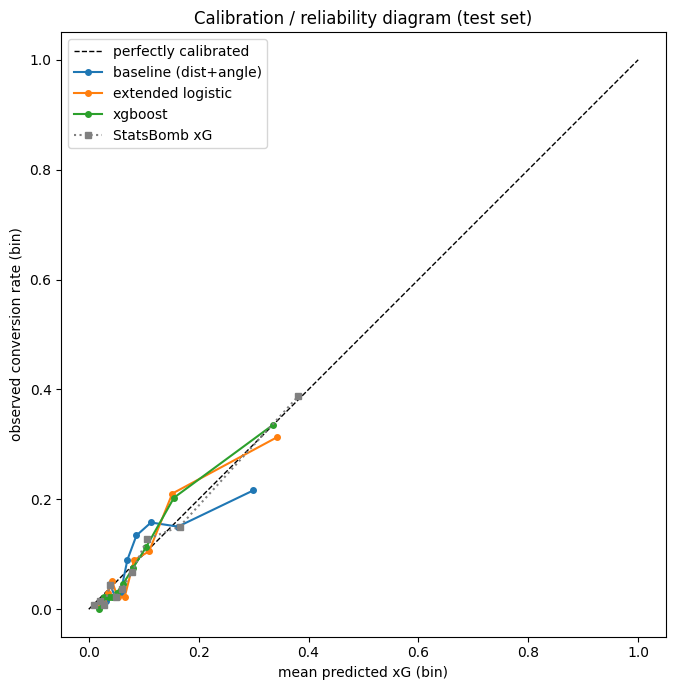

In [24]:
# --- Calibration curves (reliability diagrams) -----------------------------
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
for name, p in pred_store.items():
    frac_pos, mean_pred = calibration_curve(test["goal"], p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", ms=4, label=name)
# StatsBomb reference
frac_pos, mean_pred = calibration_curve(test["goal"], test_sb_xg, n_bins=10, strategy="quantile")
ax.plot(mean_pred, frac_pos, marker="s", ms=4, ls=":", color="grey", label="StatsBomb xG")
ax.set_xlabel("mean predicted xG (bin)"); ax.set_ylabel("observed conversion rate (bin)")
ax.set_title("Calibration / reliability diagram (test set)")
ax.legend(); ax.set_aspect("equal"); fig.tight_layout(); plt.show()

**Reading calibration.** Points on the dashed diagonal mean predicted xG equals
observed conversion in that bin. This is the single most important plot in the
notebook: a well-calibrated model can be *summed* to give meaningful expected-goal
totals. We expect the logistic models to be close to the diagonal (logistic
regression is naturally well-calibrated); watch whether XGBoost drifts, which
would flag over/under-confidence despite a competitive log-loss.

In [25]:
# --- Aggregate check: summed predicted xG vs actual goals, per team --------
agg = test[["team_name", "goal"]].copy()
agg["xg_baseline"] = pred_store["baseline (dist+angle)"]
agg["xg_extended"] = pred_store["extended logistic"]
agg["xg_xgboost"] = pred_store["xgboost"]
agg["xg_statsbomb"] = test_sb_xg

team_tbl = (agg.groupby("team_name")
            .agg(shots=("goal", "size"), actual_goals=("goal", "sum"),
                 xg_baseline=("xg_baseline", "sum"),
                 xg_extended=("xg_extended", "sum"),
                 xg_xgboost=("xg_xgboost", "sum"),
                 xg_statsbomb=("xg_statsbomb", "sum"))
            .sort_values("actual_goals", ascending=False).round(1))
print("Summed xG vs actual goals per team (test set), top 15 by goals:")
print(team_tbl.head(15).to_string())

print("\nTest-set totals:")
print(f"  actual goals         : {agg['goal'].sum()}")
for c in ["xg_baseline", "xg_extended", "xg_xgboost", "xg_statsbomb"]:
    print(f"  summed {c:<14}: {agg[c].sum():.1f}")

Summed xG vs actual goals per team (test set), top 15 by goals:
             shots  actual_goals  xg_baseline  xg_extended  xg_xgboost  xg_statsbomb
team_name                                                                           
Spain          209            17         19.1         19.9        19.0          19.9
Netherlands     55             9          5.7          6.0         7.2           8.3
Switzerland     57             8          5.3          5.4         6.1           6.8
Denmark         56             7          4.8          4.9         4.8           5.2
England         74             7          9.0          8.3         8.0           8.5
Argentina       42             6          3.1          3.5         3.8           4.1
Portugal        76             6          7.3          7.7         8.0           8.1
Croatia         45             6          5.0          6.1         4.7           5.2
France          99             6          8.9          9.1         8.6           9.0
U

**Reading the aggregate check.** A good xG model's summed predictions should track
actual goals both in the grand total and team by team. Small differences are
expected (finishing skill, variance, small samples); large systematic gaps would
signal miscalibration. Compare each model's total to the actual goal count above.

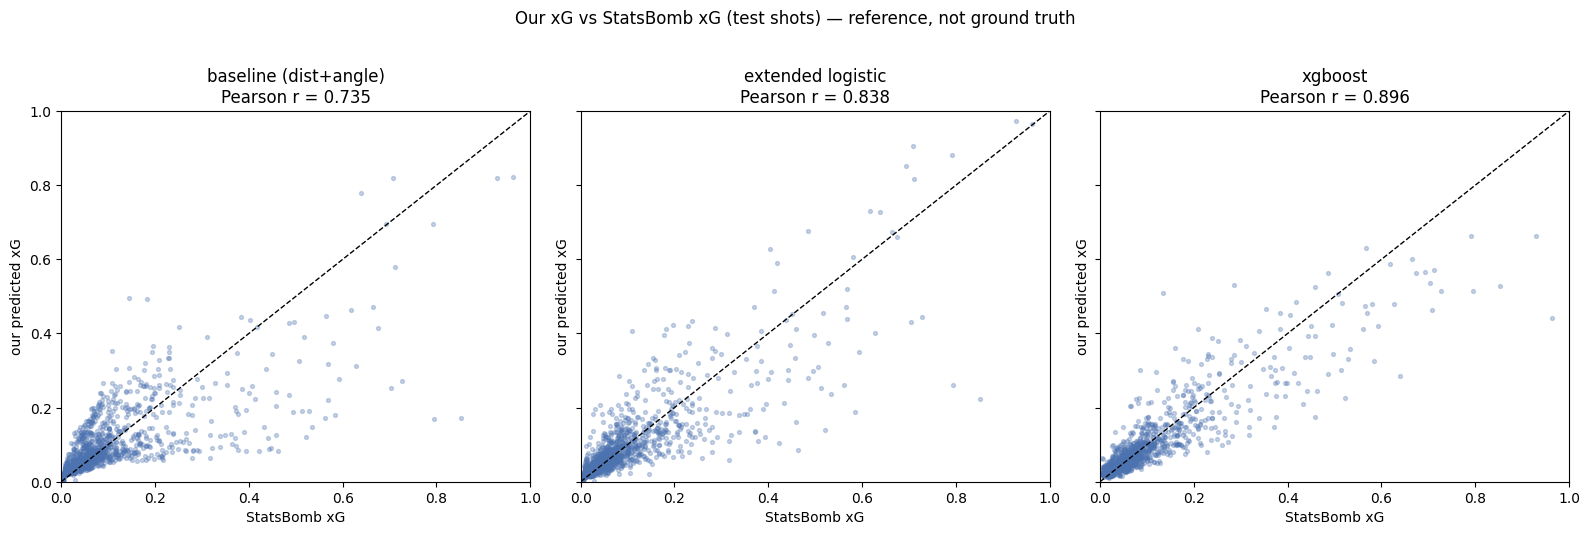

In [26]:
# --- Benchmark vs StatsBomb xG per shot (scatter + correlation) ------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharex=True, sharey=True)
for ax, name in zip(axes, ["baseline (dist+angle)", "extended logistic", "xgboost"]):
    p = pred_store[name]
    r = np.corrcoef(p, test_sb_xg)[0, 1]
    ax.scatter(test_sb_xg, p, s=8, alpha=0.3, color="#4C72B0")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"{name}\nPearson r = {r:.3f}")
    ax.set_xlabel("StatsBomb xG"); ax.set_ylabel("our predicted xG")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.suptitle("Our xG vs StatsBomb xG (test shots) — reference, not ground truth", y=1.02)
fig.tight_layout(); plt.show()

**Where and why we differ from StatsBomb.** StatsBomb's model uses far richer
inputs than our baseline — full freeze-frame geometry, goalkeeper positioning,
shot technique, pass height/type of the assist, and more. So:

* the **baseline** correlates strongly but cannot separate an open net from a
  crowded one at the same distance/angle, so it compresses toward the middle;
* the **extended logistic** and especially the **XGBoost** model (which sees
  defenders-in-cone and GK distance) track StatsBomb more tightly;
* the biggest disagreements are exactly the shots where off-ball context matters —
  point-blank chances with defenders on the line (StatsBomb lower than our
  geometry-only view) and clear one-on-ones (StatsBomb higher). We treat
  StatsBomb as a strong reference, not truth.

## 8. Visualisations with `mplsoccer`

Three views: (1) a **shot map** coloured/sized by predicted xG with goals marked;
(2) the signature **xG surface** — the fitted baseline model's goal probability
across the whole pitch, making its geometry visible; (3) the model's
**coefficients / feature importances**.

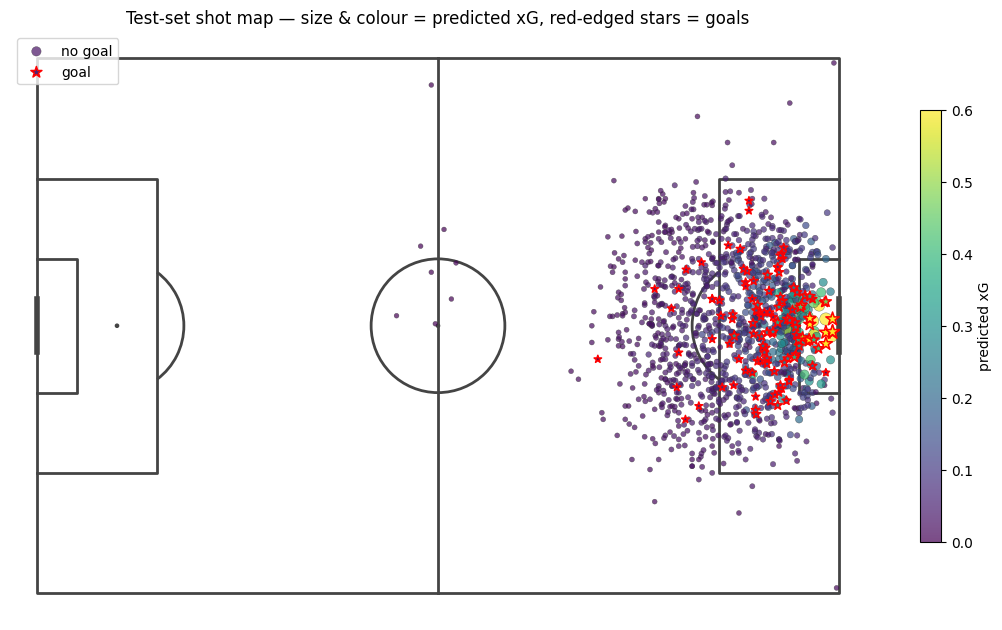

In [27]:
from mplsoccer import Pitch

# --- (1) Shot map: test shots, size/colour = predicted xG (extended model) --
pitch = Pitch(pitch_type="statsbomb", line_color="#444444", pitch_color="white")
fig, ax = pitch.draw(figsize=(11, 7.5))
p_show = pred_store["extended logistic"]
is_goal = test["goal"].to_numpy() == 1
sc = pitch.scatter(test["x"][~is_goal], test["y"][~is_goal], s=80 * p_show[~is_goal] + 12,
                   c=p_show[~is_goal], cmap="viridis", vmin=0, vmax=0.6,
                   edgecolors="#333333", linewidth=0.3, alpha=0.7, ax=ax, label="no goal")
pitch.scatter(test["x"][is_goal], test["y"][is_goal], s=80 * p_show[is_goal] + 30,
              c=p_show[is_goal], cmap="viridis", vmin=0, vmax=0.6, marker="*",
              edgecolors="red", linewidth=1.1, ax=ax, label="goal")
ax.legend(loc="upper left")
fig.colorbar(sc, ax=ax, shrink=0.6, label="predicted xG")
ax.set_title("Test-set shot map — size & colour = predicted xG, red-edged stars = goals")
plt.show()

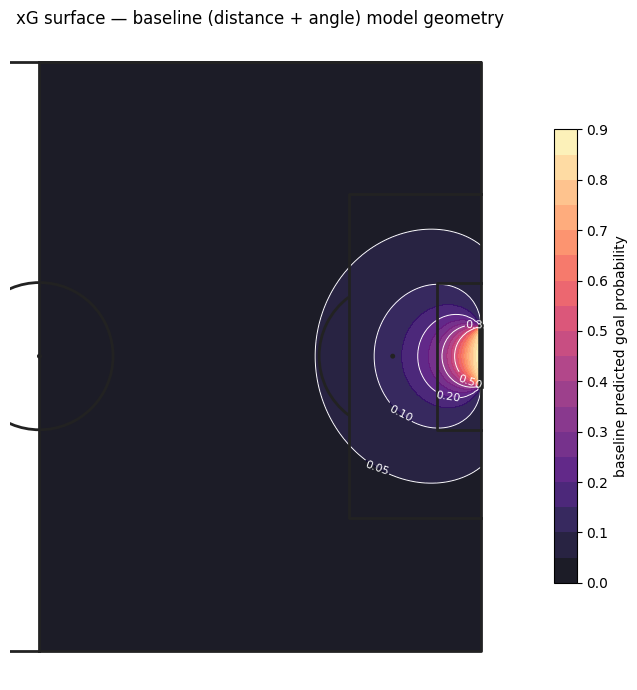

In [28]:
# --- (2) The xG surface: baseline model probability across the pitch -------
# Build a grid over the attacking half, compute distance+angle, predict.
gx = np.linspace(60, 120, 120)
gy = np.linspace(0, 80, 160)
GX, GY = np.meshgrid(gx, gy)
grid_dist = shot_distance(GX.ravel(), GY.ravel())
grid_ang = shot_angle(GX.ravel(), GY.ravel())
grid_X = np.column_stack([grid_dist, grid_ang])
surface = baseline_raw.predict_proba(grid_X)[:, 1].reshape(GX.shape)

pitch = Pitch(pitch_type="statsbomb", line_color="#222222", pitch_color="white",
              half=True)
fig, ax = pitch.draw(figsize=(9, 7))
cf = ax.contourf(GX, GY, surface, levels=20, cmap="magma", alpha=0.9, zorder=0.5)
cs = ax.contour(GX, GY, surface, levels=[0.05, 0.1, 0.2, 0.35, 0.5],
                colors="white", linewidths=0.7, zorder=0.6)
ax.clabel(cs, inline=True, fontsize=8, fmt="%.2f")
fig.colorbar(cf, ax=ax, shrink=0.7, label="baseline predicted goal probability")
ax.set_title("xG surface — baseline (distance + angle) model geometry")
plt.show()

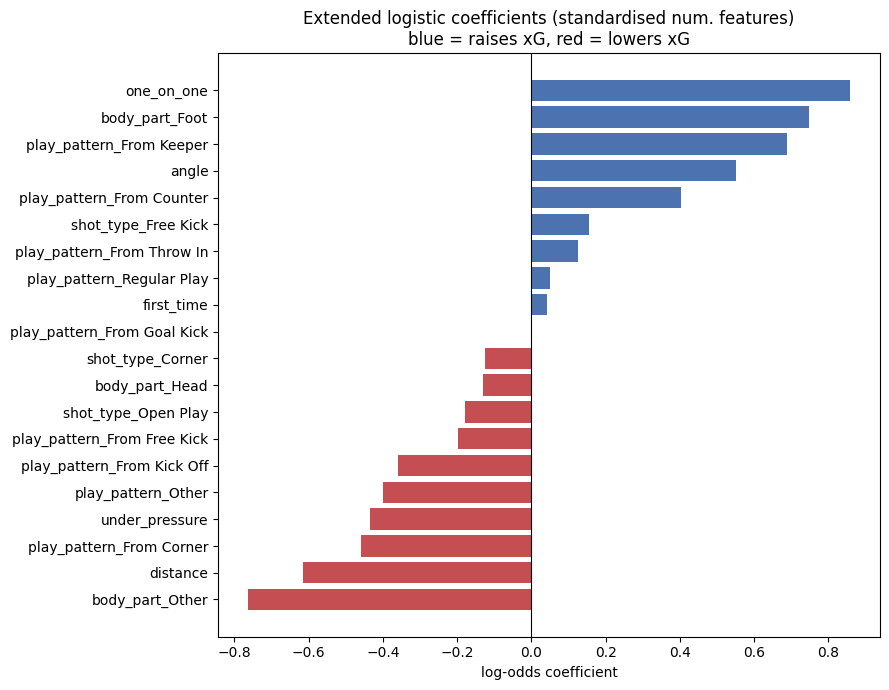

In [29]:
# --- (3a) Baseline & extended logistic coefficients ------------------------
# Extended model coefficients with readable names.
ext_logit = extended.named_steps["logit"]
ohe = extended.named_steps["pre"].named_transformers_["cat"]
feat_names = (NUM_FEATURES
              + list(ohe.get_feature_names_out(CAT_FEATURES))
              + BIN_FEATURES)
coef = pd.Series(ext_logit.coef_[0], index=feat_names).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in coef.values]
ax.barh(coef.index, coef.values, color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Extended logistic coefficients (standardised num. features)\n"
             "blue = raises xG, red = lowers xG")
ax.set_xlabel("log-odds coefficient")
fig.tight_layout(); plt.show()

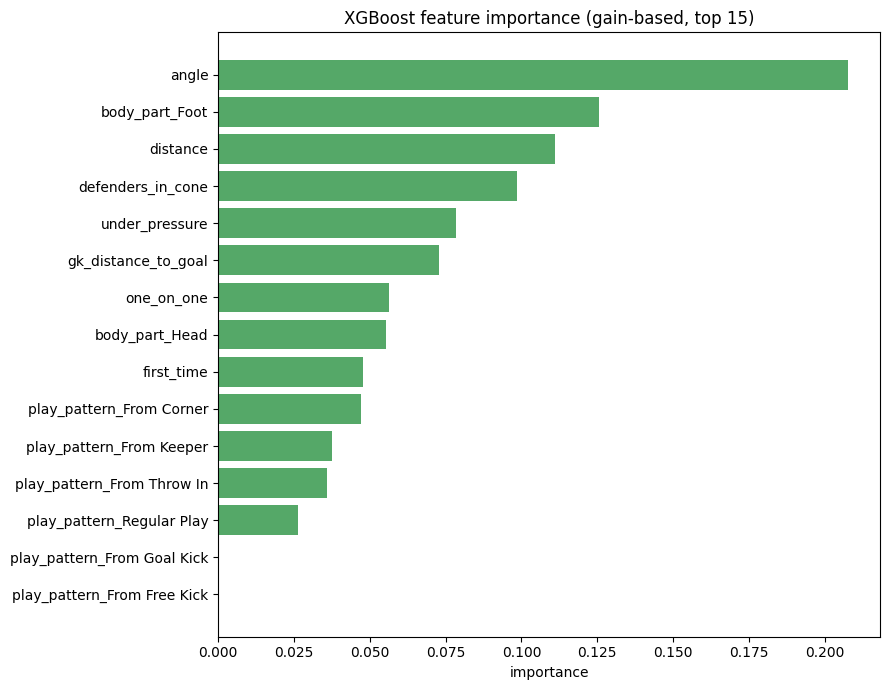

In [30]:
# --- (3b) XGBoost feature importance ---------------------------------------
xgb_model = gboost.named_steps["xgb"]
# Recover the true output feature names straight from the fitted
# ColumnTransformer. This includes any missing-value indicator columns the
# imputer added (only created for numeric features that actually had NaNs),
# so the names always line up with the importance vector.
raw_names = gboost.named_steps["pre"].get_feature_names_out()
gb_names = [n.split("__", 1)[-1] for n in raw_names]  # drop num__/cat__/bin__ prefix
importances = xgb_model.feature_importances_
assert len(gb_names) == len(importances), (len(gb_names), len(importances))
imp = pd.Series(importances, index=gb_names).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(imp.index, imp.values, color="#55A868")
ax.set_title("XGBoost feature importance (gain-based, top 15)")
ax.set_xlabel("importance")
fig.tight_layout(); plt.show()

## 9. Conclusions

**What drives xG.** Overwhelmingly **distance**, then **angle** — the two-feature
Sumpter baseline already captures most of the signal and is well-calibrated. Adding
shot context (**body part**, **shot situation / play pattern**, **under-pressure**,
**first-time**, **one-on-one**) gives a real but secondary improvement in log-loss
and AIC. The freeze-frame features (**defenders in the shot cone**, **goalkeeper
distance**) are what let the boosted model close most of the remaining gap to
StatsBomb, because they encode *who is in the way* — the information pure geometry
cannot see.

**Model comparison.** Gains in AUC from baseline → extended → XGBoost are modest;
the more important story is calibration and log-loss. The logistic models are
naturally well-calibrated and fully interpretable; XGBoost edges them on log-loss
when the freeze-frame features are available but must be watched for calibration
drift.

**Limitations.**
* Trained on four men's international tournaments only — style/finishing may not
  transfer to club football or the women's game without refitting.
* No shot **technique** (volley/half-volley), no assist/pass-height context, no
  explicit goalkeeper *angle* (only distance), no defender *pressure distance*.
* Freeze-frame features are absent for a small fraction of shots (imputed).
* xG is a model of *chance quality*, not finishing skill; per-player finishing
  effects are deliberately not modelled.

**What I'd add next.** Shot technique and the assist type/height; goalkeeper
positioning relative to the shot line (not just distance to centre); distance to
the nearest defender; a proper isotonic/Platt **recalibration** layer on the
boosted model; and cross-competition validation (train on internationals, test on
a club league) to measure transfer.

In [31]:
# --- Save the fitted models + metadata to disk (joblib) --------------------
import joblib, json, datetime as dt

MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)
artifact = {
    "baseline_pipeline": baseline,
    "baseline_raw_logit": baseline_raw,
    "extended_pipeline": extended,
    "xgboost_pipeline": gboost,
    "feature_sets": {"baseline": BASE_FEATURES, "extended": EXT_FEATURES, "xgboost": GB_FEATURES},
    "geometry": {"GOAL_X": GOAL_X, "GOAL_CENTER_Y": GOAL_CENTER_Y,
                 "POST_A_Y": POST_A_Y, "POST_B_Y": POST_B_Y},
    "competitions": CHOSEN,
    "test_metrics": metrics.to_dict(),
    "random_seed": RANDOM_SEED,
    "created": dt.datetime.now().isoformat(timespec="seconds"),
}
out = MODEL_DIR / "xg_models.joblib"
joblib.dump(artifact, out)
print("Saved model artifact ->", out.resolve())

# Round-trip check that the saved model loads and predicts.
reloaded = joblib.load(out)
chk = reloaded["extended_pipeline"].predict_proba(test[EXT_FEATURES])[:5, 1]
print("Reload OK. Sample predictions:", np.round(chk, 3))
print("\nDone. Notebook ran top to bottom.")

Saved model artifact -> /Users/prithvirajsangramsinhpatil/FOOTBALL-DATA-ANALYSIS/FOOTBALL-DATA-ANALYSIS/expected-goals-model/models/xg_models.joblib
Reload OK. Sample predictions: [0.027 0.023 0.123 0.022 0.049]

Done. Notebook ran top to bottom.
